In [1]:
import pandas as pd
import numpy as np

# Load the datasets
customers = pd.read_csv('data/raw/olist_customers_dataset.csv')
orders = pd.read_csv('data/raw/olist_orders_dataset.csv')
order_items = pd.read_csv('data/raw/olist_order_items_dataset.csv')
products = pd.read_csv('data/raw/olist_products_dataset.csv')

print("✓ Data loaded!")
print(f"\nCustomers: {customers.shape}")
print(f"Orders: {orders.shape}")
print(f"Order items: {order_items.shape}")
print(f"Products: {products.shape}")

✓ Data loaded!

Customers: (99441, 5)
Orders: (99441, 8)
Order items: (112650, 7)
Products: (32951, 9)


In [2]:
print("=== CUSTOMERS ===")
print(customers.columns.tolist())
print("\nFirst row:")
print(customers.head(1))

print("\n=== ORDERS ===")
print(orders.columns.tolist())
print("\nFirst row:")
print(orders.head(1))

print("\n=== ORDER ITEMS ===")
print(order_items.columns.tolist())
print("\nFirst row:")
print(order_items.head(1))

print("\n=== PRODUCTS ===")
print(products.columns.tolist())
print("\nFirst row:")
print(products.head(1))

=== CUSTOMERS ===
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

First row:
                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   

   customer_zip_code_prefix customer_city customer_state  
0                     14409        franca             SP  

=== ORDERS ===
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

First row:
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017

In [3]:
df=orders.merge(customers, on="customer_id", how="left")
print("merged dataset")
print(f"data_shape:{df.shape}")
print(f"data:{df.columns.to_list}")

merged dataset
data_shape:(99441, 12)
data:<bound method IndexOpsMixin.tolist of Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'customer_unique_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state'],
      dtype='str')>


In [4]:
df=df.merge(order_items, on="order_id", how="left")
print("merged dataset")
print(f"data_shape:{df.shape}")
print(f"data:{df.columns.to_list}")

merged dataset
data_shape:(113425, 18)
data:<bound method IndexOpsMixin.tolist of Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'customer_unique_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')>


In [5]:
df=df.merge(products, on="product_id", how="left")
print("merged dataset")
print(f"data_shape:{df.shape}")
print(f"data:{df.columns.to_list}")

merged dataset
data_shape:(113425, 26)
data:<bound method IndexOpsMixin.tolist of Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'customer_unique_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='str')>


In [6]:
print(df.isnull().sum())

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 161
order_delivered_carrier_date     1968
order_delivered_customer_date    3229
order_estimated_delivery_date       0
customer_unique_id                  0
customer_zip_code_prefix            0
customer_city                       0
customer_state                      0
order_item_id                     775
product_id                        775
seller_id                         775
shipping_limit_date               775
price                             775
freight_value                     775
product_category_name            2378
product_name_lenght              2378
product_description_lenght       2378
product_photos_qty               2378
product_weight_g                  793
product_length_cm                 793
product_height_cm                 793
product_width_cm                  793
dtype: int64

In [7]:
needed_cols = [
    'customer_id',
    'customer_state', 
    'order_purchase_timestamp',
    'price',
    'product_category_name',
    'order_status'
]
df = df.dropna(subset=['price', 'product_category_name',])
df=df[needed_cols].copy()
print(f"shape:{df.shape}")
print(f"data: {df.head(0)}")
print(f"{df.isnull().sum()}")

shape:(111047, 6)
data: Empty DataFrame
Columns: [customer_id, customer_state, order_purchase_timestamp, price, product_category_name, order_status]
Index: []
customer_id                 0
customer_state              0
order_purchase_timestamp    0
price                       0
product_category_name       0
order_status                0
dtype: int64


In [8]:
df.info()
df.head()
print("\nUNIQUE VALUES:")
print(f"customer_state: {df['customer_state'].nunique()} unique")
print(f"customer_state values: {df['customer_state'].unique()[:10]}")
print(f"\nproduct_category_name: {df['product_category_name'].nunique()} unique")
print(f"product_category_name values: {df['product_category_name'].unique()[:10]}")
print(f"\norder_status: {df['order_status'].unique()}")
print(f"\nprice range: {df['price'].min()} to {df['price'].max()}")

<class 'pandas.DataFrame'>
Index: 111047 entries, 0 to 113424
Data columns (total 6 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   customer_id               111047 non-null  str    
 1   customer_state            111047 non-null  str    
 2   order_purchase_timestamp  111047 non-null  str    
 3   price                     111047 non-null  float64
 4   product_category_name     111047 non-null  str    
 5   order_status              111047 non-null  str    
dtypes: float64(1), str(5)
memory usage: 5.9 MB

UNIQUE VALUES:
customer_state: 27 unique
customer_state values: <StringArray>
['SP', 'BA', 'GO', 'RN', 'PR', 'RJ', 'RS', 'MG', 'SC', 'RR']
Length: 10, dtype: str

product_category_name: 73 unique
product_category_name values: <StringArray>
[ 'utilidades_domesticas',             'perfumaria',             'automotivo',
               'pet_shop',              'papelaria',       'moveis_decoracao',
      'move

In [9]:
df=df[df['order_status']=="delivered"].copy()
df.info()

<class 'pandas.DataFrame'>
Index: 108660 entries, 0 to 113424
Data columns (total 6 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   customer_id               108660 non-null  str    
 1   customer_state            108660 non-null  str    
 2   order_purchase_timestamp  108660 non-null  str    
 3   price                     108660 non-null  float64
 4   product_category_name     108660 non-null  str    
 5   order_status              108660 non-null  str    
dtypes: float64(1), str(5)
memory usage: 5.8 MB


In [10]:
df['order_purchase_timestamp']=pd.to_datetime(df['order_purchase_timestamp'])
df.dtypes

customer_id                            str
customer_state                         str
order_purchase_timestamp    datetime64[us]
price                              float64
product_category_name                  str
order_status                           str
dtype: object

In [11]:
df['month']=df['order_purchase_timestamp'].dt.month

df['season']=df['month'].apply(lambda x:
                               'Summer' if x in [12,1,2] else
                               'Winter' if x in [6,7,8] else
                               'Autumn' if x in [3, 4, 5] else "Spring"
                              )
state_income_map = {
    'SP': 0.85, 'RJ': 0.80, 'MG': 0.65, 'RS': 0.78, 'BA': 0.48, 
    'PE': 0.42, 'PR': 0.70, 'SC': 0.75, 'ES': 0.70, 'DF': 0.90,
    'PA': 0.45, 'CE': 0.45, 'PB': 0.40, 'GO': 0.65, 'AM': 0.50
}
df['income_proxy'] = df['customer_state'].map(state_income_map).fillna(0.55)

print("✓ Features engineered")
print(df[['season', 'income_proxy', 'month']].head(10))
print(f"\nSeasons: {df['season'].unique()}")
print(f"Income proxy range: {df['income_proxy'].min()} to {df['income_proxy'].max()}")

✓ Features engineered
    season  income_proxy  month
0   Spring          0.85     10
1   Winter          0.48      7
2   Winter          0.65      8
3   Spring          0.55     11
4   Summer          0.85      2
5   Winter          0.70      7
7   Autumn          0.80      5
8   Summer          0.78      1
9   Winter          0.85      7
10  Autumn          0.80      5

Seasons: <StringArray>
['Spring', 'Winter', 'Summer', 'Autumn']
Length: 4, dtype: str
Income proxy range: 0.4 to 0.9


In [12]:
category_median=df.groupby('product_category_name')['price'].transform('median')
df['discount_given']=(df['price']<(category_median*0.85)).astype(int)
df['discount_amount'] = (category_median - df['price']).clip(0, None)
print("✓ Discount engineered")
print(f"Discount rate: {df['discount_given'].mean():.1%}")
print(f"Avg discount amount: ${df['discount_amount'].mean():.2f}")
print(df[['price', 'discount_given', 'discount_amount']].head(10))

✓ Discount engineered
Discount rate: 41.8%
Avg discount amount: $17.32
     price  discount_given  discount_amount
0    29.99               1            29.71
1   118.70               0             0.00
2   159.90               0             0.00
3    45.00               1            44.70
4    19.90               1            59.10
5   147.90               0             0.00
7    59.99               1            24.91
8    19.90               1            45.59
9   149.99               0             0.00
10   99.00               0             0.00


In [13]:
# Calculate tenure (days since first purchase)
customer_tenure = df.groupby('customer_id')['order_purchase_timestamp'].agg(['min', 'max'])
customer_tenure.columns = ['first_order_date', 'last_order_date']

# Days as customer
max_date = df['order_purchase_timestamp'].max()
customer_tenure['tenure_days'] = (max_date - customer_tenure['first_order_date']).dt.days

# Purchase frequency (how many items did they buy?)
customer_tenure['purchase_frequency'] = df.groupby('customer_id').size()

# Engagement (simple: more items = more engaged)
customer_tenure['engagement_score'] = customer_tenure['purchase_frequency'] / customer_tenure['purchase_frequency'].max()

print("✓ Tenure and engagement calculated")
print(f"Tenure range: {customer_tenure['tenure_days'].min()} to {customer_tenure['tenure_days'].max()} days")
print(f"Purchase frequency: {customer_tenure['purchase_frequency'].min()} to {customer_tenure['purchase_frequency'].max()} items")
print(customer_tenure.head(10))

✓ Tenure and engagement calculated
Tenure range: 0 to 713 days
Purchase frequency: 1 to 21 items
                                    first_order_date     last_order_date  \
customer_id                                                                
00012a2ce6f8dcda20d059ce98491703 2017-11-14 16:08:26 2017-11-14 16:08:26   
000161a058600d5901f007fab4c27140 2017-07-16 09:40:32 2017-07-16 09:40:32   
0001fd6190edaaf884bcaf3d49edf079 2017-02-28 11:06:43 2017-02-28 11:06:43   
0002414f95344307404f0ace7a26f1d5 2017-08-16 13:09:20 2017-08-16 13:09:20   
000379cdec625522490c315e70c7a9fb 2018-04-02 13:42:17 2018-04-02 13:42:17   
0004164d20a9e969af783496f3408652 2017-04-12 08:35:12 2017-04-12 08:35:12   
000419c5494106c306a97b5635748086 2018-03-02 17:47:40 2018-03-02 17:47:40   
00046a560d407e99b969756e0b10f282 2017-12-18 11:08:30 2017-12-18 11:08:30   
00050bf6e01e69d5c0fd612f1bcfb69c 2017-09-17 16:04:44 2017-09-17 16:04:44   
000598caf2ef4117407665ac33275130 2018-08-11 12:14:35 2018-08-11 12:

In [14]:
# Final customer dataset
customer_final = df.groupby('customer_id').agg({
    'customer_state': 'first',
    'income_proxy': 'first',
    'season': lambda x: x.mode()[0] if len(x.mode()) > 0 else 'Spring',
    'discount_given': 'max',  # FIXED: was 'mean', now 'max'
    'discount_amount': 'mean',
    'price': 'mean'
}).reset_index()

customer_final = customer_final.merge(customer_tenure.reset_index(), on='customer_id')

# FIXED: Engineer outcome properly - repeat purchase (bought 2+ times)
customer_final['purchase_made'] = (customer_final['purchase_frequency'] > 1).astype(int)

# Rename columns
customer_final.columns = ['customer_id', 'customer_state', 'income_proxy', 'favorite_season',
                          'discount_given', 'discount_amount', 'avg_price',
                          'first_order_date', 'last_order_date', 'tenure_days',
                          'purchase_frequency', 'engagement_score', 'purchase_made']

print(f"✓ Aggregated to {len(customer_final)} customers")
print(f"Shape: {customer_final.shape}")
print(customer_final.head())

✓ Final customer dataset created
Shape: (95146, 13)
                        customer_id customer_state  income_proxy  \
0  00012a2ce6f8dcda20d059ce98491703             SP          0.85   
1  000161a058600d5901f007fab4c27140             MG          0.65   
2  0001fd6190edaaf884bcaf3d49edf079             ES          0.70   
3  0002414f95344307404f0ace7a26f1d5             MG          0.65   
4  000379cdec625522490c315e70c7a9fb             SP          0.85   

  favorite_season  discount_given  discount_amount  avg_price  \
0          Spring             0.0              0.0      89.80   
1          Winter             1.0             25.0      54.90   
2          Summer             0.0              0.0     179.99   
3          Winter             0.0              0.0     149.90   
4          Autumn             0.0              0.0      93.00   

     first_order_date     last_order_date  tenure_days  purchase_frequency  \
0 2017-11-14 16:08:26 2017-11-14 16:08:26          287                

In [15]:
# Create output directory
import os
os.makedirs('data/processed', exist_ok=True)

# Save to CSV
customer_final.to_csv('data/processed/customer_data.csv', index=False)

print("✓ Data saved!")
print(f"File: data/processed/customer_data.csv")
print(f"Rows: {len(customer_final)}")
print(f"Columns: {len(customer_final.columns)}")

# Summary statistics
print("\n" + "="*60)
print("SUMMARY STATISTICS")
print("="*60)
print(f"Income proxy: {customer_final['income_proxy'].min():.2f} to {customer_final['income_proxy'].max():.2f}")
print(f"Discount rate: {customer_final['discount_given'].mean():.1%}")
print(f"Discount amount: ${customer_final['discount_amount'].mean():.2f}")
print(f"Tenure: {customer_final['tenure_days'].min()} to {customer_final['tenure_days'].max()} days")
print(f"Purchase frequency: {customer_final['purchase_frequency'].min()} to {customer_final['purchase_frequency'].max()}")
print(f"Engagement: {customer_final['engagement_score'].min():.3f} to {customer_final['engagement_score'].max():.3f}")

✓ Data saved!
File: data/processed/customer_data.csv
Rows: 95146
Columns: 13

SUMMARY STATISTICS
Income proxy: 0.40 to 0.90
Discount rate: 40.2%
Discount amount: $16.46
Tenure: 0 to 713 days
Purchase frequency: 1 to 21
Engagement: 0.048 to 1.000


In [16]:
from dowhy import CausalModel

print("\n" + "="*70)
print("WEEK 1: CAUSAL GRAPHING WITH DOWHY")
print("="*70)

# Define causal graph
causal_graph = """
digraph {
income_proxy -> discount_given;
income_proxy -> purchase_made;
tenure_days -> discount_given;
tenure_days -> purchase_made;
engagement_score -> discount_given;
engagement_score -> purchase_made;
favorite_season -> purchase_made;
discount_given -> purchase_made;
}
"""

print("\n📊 Causal Graph (DAG):")
print(causal_graph)

# Create causal model
print("\n🔍 Creating CausalModel...")
model = CausalModel(
    data=customer_final,
    treatment='discount_given',
    outcome='purchase_made',
    common_causes=['income_proxy', 'tenure_days', 'engagement_score', 'favorite_season'],
    graph=causal_graph
)

print("✓ CausalModel created")

# Identify effect
print("\n🔬 Identifying causal effect...")
identified_estimand = model.identify_effect(proceed_when_unidentifiable=True)

print("\n📍 IDENTIFIED ESTIMAND:")
print(identified_estimand)


WEEK 1: CAUSAL GRAPHING WITH DOWHY

📊 Causal Graph (DAG):

digraph {
income_proxy -> discount_given;
income_proxy -> purchase_made;
tenure_days -> discount_given;
tenure_days -> purchase_made;
engagement_score -> discount_given;
engagement_score -> purchase_made;
favorite_season -> purchase_made;
discount_given -> purchase_made;
}


🔍 Creating CausalModel...
✓ CausalModel created

🔬 Identifying causal effect...

📍 IDENTIFIED ESTIMAND:
Estimand type: nonparametric-ate

### Estimand : 1
Estimand name: backdoor
Estimand expression:
        d                                                                    
─────────────────(E[purchase_made|tenure_days,engagement_score,income_proxy])
d[discount_given]                                                            
Estimand assumption 1, Unconfoundedness: If U→{discount_given} and U→purchase_made then P(purchase_made|discount_given,tenure_days,engagement_score,income_proxy,U) = P(purchase_made|discount_given,tenure_days,engagement_score,inco

In [ ]:
# WEEK 2: DOUBLE MACHINE LEARNING

Train outcome and propensity models to estimate Individual Treatment Effects (ITEs)

In [17]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

print("✓ Libraries loaded")

✓ Libraries loaded


In [24]:
# Load processed data
df = pd.read_csv('data/processed/customer_data.csv')

print(f"✓ Data loaded: {len(df)} customers")
print(f"Columns: {df.columns.tolist()}")

✓ Data loaded: 95146 customers
Columns: ['customer_id', 'customer_state', 'income_proxy', 'favorite_season', 'discount_given', 'discount_amount', 'avg_price', 'first_order_date', 'last_order_date', 'tenure_days', 'purchase_frequency', 'engagement_score', 'purchase_made']


In [25]:
# Encode season to numbers
season_map = {'Winter': 0, 'Spring': 1, 'Summer': 2, 'Autumn': 3}
df['season_encoded'] = df['favorite_season'].map(season_map)

# Define features, treatment, outcome
features = ['income_proxy', 'tenure_days', 'engagement_score', 'season_encoded']
X = df[features].copy()
T = df['discount_given'].copy()
Y = df['purchase_made'].copy()

print("✓ Data prepared")
print(f"\nFeatures (X): {X.shape}")
print(f"Treatment (T): {T.shape}")
print(f"Outcome (Y): {Y.shape}")

print(f"\nFeatures: {features}")
print(f"\nOutcome distribution:")
print(Y.value_counts())
print(f"Repeat purchase rate: {Y.mean():.1%}")

✓ Data prepared

Features (X): (95146, 4)
Treatment (T): (95146,)
Outcome (Y): (95146,)

Features: ['income_proxy', 'tenure_days', 'engagement_score', 'season_encoded']

Outcome distribution:
purchase_made
0    85654
1     9492
Name: count, dtype: int64
Repeat purchase rate: 10.0%


In [26]:
print("="*70)
print("EXPLORATORY DATA ANALYSIS (EDA)")
print("="*70)

# 1. Check feature distributions
print("\n📊 Feature Statistics:")
print(X.describe())

# 2. Check correlations
print("\n📈 Correlations with Outcome:")
correlation_with_outcome = X.copy()
correlation_with_outcome['purchase_made'] = Y
print(correlation_with_outcome.corr()['purchase_made'].sort_values(ascending=False))

# 3. Treatment effect (basic)
print("\n💰 Basic Treatment Analysis:")
print(f"Purchase rate WITHOUT discount: {Y[T == 0].mean():.1%}")
print(f"Purchase rate WITH discount: {Y[T == 1].mean():.1%}")
print(f"Observed difference: {(Y[T == 1].mean() - Y[T == 0].mean()):.1%}")

# 4. Class balance
print("\n⚖️ Class Balance:")
print(f"Repeat buyers (1): {(Y == 1).sum()} ({(Y == 1).mean():.1%})")
print(f"One-time buyers (0): {(Y == 0).sum()} ({(Y == 0).mean():.1%})")

# 5. Feature missing values
print("\n🔍 Missing Values:")
print(X.isnull().sum())

EXPLORATORY DATA ANALYSIS (EDA)

📊 Feature Statistics:
       income_proxy   tenure_days  engagement_score  season_encoded
count  95146.000000  95146.000000      95146.000000    95146.000000
mean       0.752434    238.392145          0.054383        1.510699
std        0.125082    152.842128          0.025649        1.212906
min        0.400000      0.000000          0.047619        0.000000
25%        0.650000    114.000000          0.047619        0.000000
50%        0.800000    219.000000          0.047619        2.000000
75%        0.850000    348.000000          0.047619        3.000000
max        0.900000    713.000000          1.000000        3.000000

📈 Correlations with Outcome:
purchase_made       1.000000
engagement_score    0.792153
income_proxy        0.016638
season_encoded      0.005825
tenure_days         0.001356
Name: purchase_made, dtype: float64

💰 Basic Treatment Analysis:
Purchase rate WITHOUT discount: 7.4%
Purchase rate WITH discount: 13.7%
Observed difference: 

EXPLORATORY DATA ANALYSIS (EDA)


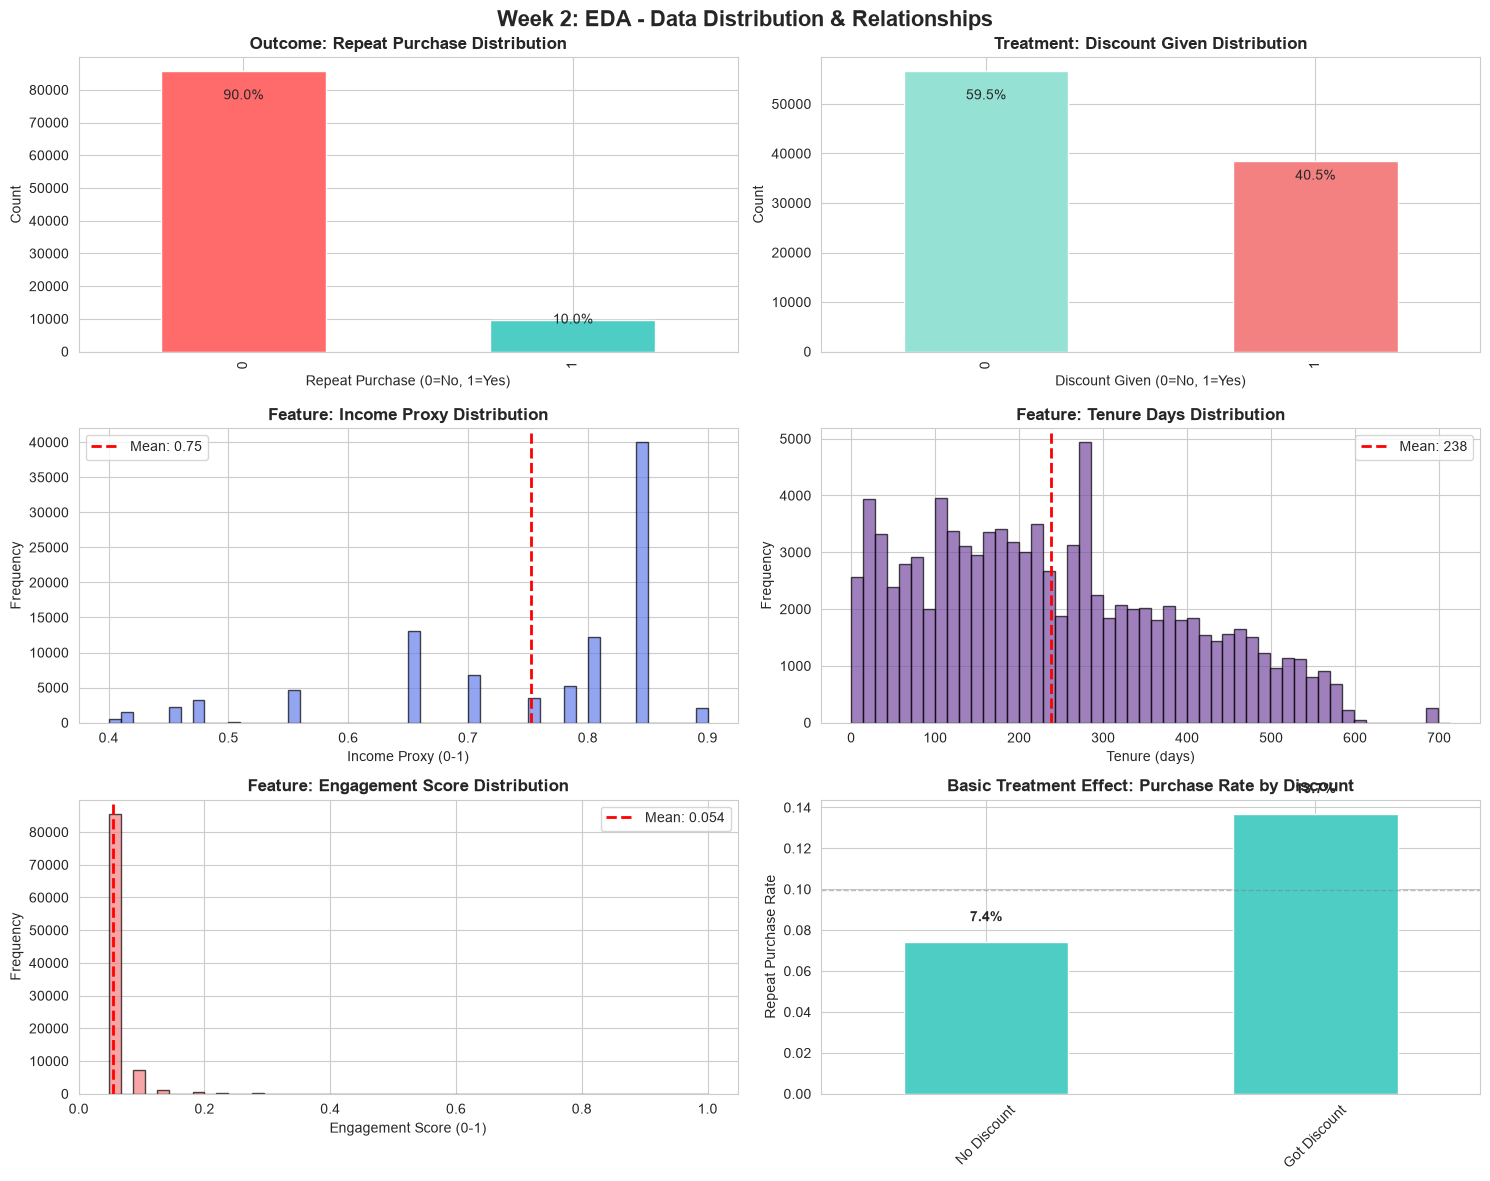

✓ EDA visualizations created and saved as 'eda_week2.png'


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

print("="*70)
print("EXPLORATORY DATA ANALYSIS (EDA)")
print("="*70)

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (15, 12)

# Create subplots
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
fig.suptitle('Week 2: EDA - Data Distribution & Relationships', fontsize=16, fontweight='bold')

# 1. Outcome distribution
ax1 = axes[0, 0]
Y.value_counts().plot(kind='bar', ax=ax1, color=['#ff6b6b', '#4ecdc4'])
ax1.set_title('Outcome: Repeat Purchase Distribution', fontweight='bold')
ax1.set_xlabel('Repeat Purchase (0=No, 1=Yes)')
ax1.set_ylabel('Count')
ax1.text(0, Y.value_counts()[0]*0.9, f'{(Y==0).mean():.1%}', ha='center', fontsize=10)
ax1.text(1, Y.value_counts()[1]*0.9, f'{(Y==1).mean():.1%}', ha='center', fontsize=10)

# 2. Treatment distribution
ax2 = axes[0, 1]
T.value_counts().plot(kind='bar', ax=ax2, color=['#95e1d3', '#f38181'])
ax2.set_title('Treatment: Discount Given Distribution', fontweight='bold')
ax2.set_xlabel('Discount Given (0=No, 1=Yes)')
ax2.set_ylabel('Count')
ax2.text(0, T.value_counts()[0]*0.9, f'{(T==0).mean():.1%}', ha='center', fontsize=10)
ax2.text(1, T.value_counts()[1]*0.9, f'{(T==1).mean():.1%}', ha='center', fontsize=10)

# 3. Feature: Income Proxy
ax3 = axes[1, 0]
ax3.hist(X['income_proxy'], bins=50, color='#667eea', alpha=0.7, edgecolor='black')
ax3.set_title('Feature: Income Proxy Distribution', fontweight='bold')
ax3.set_xlabel('Income Proxy (0-1)')
ax3.set_ylabel('Frequency')
ax3.axvline(X['income_proxy'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: {X['income_proxy'].mean():.2f}")
ax3.legend()

# 4. Feature: Tenure Days
ax4 = axes[1, 1]
ax4.hist(X['tenure_days'], bins=50, color='#764ba2', alpha=0.7, edgecolor='black')
ax4.set_title('Feature: Tenure Days Distribution', fontweight='bold')
ax4.set_xlabel('Tenure (days)')
ax4.set_ylabel('Frequency')
ax4.axvline(X['tenure_days'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: {X['tenure_days'].mean():.0f}")
ax4.legend()

# 5. Feature: Engagement Score
ax5 = axes[2, 0]
ax5.hist(X['engagement_score'], bins=50, color='#f38181', alpha=0.7, edgecolor='black')
ax5.set_title('Feature: Engagement Score Distribution', fontweight='bold')
ax5.set_xlabel('Engagement Score (0-1)')
ax5.set_ylabel('Frequency')
ax5.axvline(X['engagement_score'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: {X['engagement_score'].mean():.3f}")
ax5.legend()

# 6. Treatment Effect (Basic)
ax6 = axes[2, 1]
treatment_effect = pd.DataFrame({
    'No Discount': [Y[T == 0].mean()],
    'Got Discount': [Y[T == 1].mean()]
})
treatment_effect.T.plot(kind='bar', ax=ax6, color=['#4ecdc4', '#ff6b6b'], legend=False)
ax6.set_title('Basic Treatment Effect: Purchase Rate by Discount', fontweight='bold')
ax6.set_ylabel('Repeat Purchase Rate')
ax6.set_xticklabels(ax6.get_xticklabels(), rotation=45)
ax6.axhline(Y.mean(), color='gray', linestyle='--', linewidth=1, alpha=0.5, label='Overall mean')
ax6.text(0, Y[T == 0].mean() + 0.01, f"{Y[T == 0].mean():.1%}", ha='center', fontweight='bold')
ax6.text(1, Y[T == 1].mean() + 0.01, f"{Y[T == 1].mean():.1%}", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('eda_week2.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ EDA visualizations created and saved as 'eda_week2.png'")

In [1]:
from econml.dml import LinearDML, CausalForestDML
from econml import __version__ as econml_version
import lightgbm

print(f"✓ EconML version: {econml_version}")
print(f"✓ LightGBM version: {lightgbm.__version__}")

✓ EconML version: 0.17.0
✓ LightGBM version: 4.7.0


In [2]:
import pandas as pd

df = pd.read_csv('data/processed/customer_data.csv')

season_map = {'Winter': 0, 'Spring': 1, 'Summer': 2, 'Autumn': 3}
df['season_encoded'] = df['favorite_season'].map(season_map)

X = df[['income_proxy', 'tenure_days', 'season_encoded']].values
T = df['discount_given'].values
Y = df['purchase_made'].values

print(f"X shape: {X.shape}, nulls: {pd.isnull(X).sum()}")
print(f"T unique values: {sorted(set(T))}, mean: {T.mean():.3f}")
print(f"Y unique values: {sorted(set(Y))}, mean: {Y.mean():.3f}")
print(f"Season values mapped: {df['season_encoded'].isna().sum()} missing")

X shape: (95146, 3), nulls: 0
T unique values: [np.int64(0), np.int64(1)], mean: 0.405
Y unique values: [np.int64(0), np.int64(1)], mean: 0.100
Season values mapped: 0 missing


In [3]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier

cv = KFold(n_splits=5, shuffle=True, random_state=42)

def make_model():
    return LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbose=-1,
    )

# Outcome model: P(Y | X), out-of-fold predictions
Y_hat = cross_val_predict(make_model(), X, Y, cv=cv, method='predict_proba')[:, 1]

# Propensity model: P(T | X), out-of-fold predictions
T_hat = cross_val_predict(make_model(), X, T, cv=cv, method='predict_proba')[:, 1]

outcome_auc = roc_auc_score(Y, Y_hat)
propensity_auc = roc_auc_score(T, T_hat)

print(f"Outcome model AUC (predicts purchase_made): {outcome_auc:.3f}")
print(f"Propensity model AUC (predicts discount_given): {propensity_auc:.3f}")
print(f"Propensity range: {T_hat.min():.3f} to {T_hat.max():.3f}")

Outcome model AUC (predicts purchase_made): 0.518
Propensity model AUC (predicts discount_given): 0.540
Propensity range: 0.105 to 0.807


In [5]:
from econml.dml import LinearDML
from lightgbm import LGBMRegressor

def make_outcome_regressor():
    return LGBMRegressor(
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbose=-1,
    )

est = LinearDML(
    model_y=make_outcome_regressor(),
    model_t=make_model(),
    discrete_treatment=True,
    cv=cv,
    random_state=42,
)

est.fit(Y, T, X=X)

ate = est.ate(X)
lb, ub = est.ate_interval(X, alpha=0.05)

print(f"ATE (effect of discount on repeat purchase): {ate:.4f}")
print(f"95% CI: [{lb:.4f}, {ub:.4f}]")
print(f"Naive difference (EDA): 0.0600")

ATE (effect of discount on repeat purchase): 0.0625
95% CI: [0.0584, 0.0666]
Naive difference (EDA): 0.0600


In [6]:
import pandas as pd

df = pd.read_csv('data/processed/customer_data.csv')

print("Mean of each feature by discount group:\n")
print(df.groupby('discount_given')[['income_proxy', 'tenure_days']].mean().round(3))

print("\nDiscount rate by season:")
print(df.groupby('favorite_season')['discount_given'].agg(['mean', 'count']).round(3))

print("\nDiscount rate by income_proxy value:")
print(df.groupby('income_proxy')['discount_given'].agg(['mean', 'count']).round(3))

print("\nTenure quartiles:")
df['tenure_quartile'] = pd.qcut(df['tenure_days'], 4, labels=['Q1', 'Q2', 'Q3', 'Q4'], duplicates='drop')
print(df.groupby('tenure_quartile', observed=True)['discount_given'].agg(['mean', 'count']).round(3))

Mean of each feature by discount group:

                income_proxy  tenure_days
discount_given                           
0                      0.747      237.994
1                      0.761      238.976

Discount rate by season:
                  mean  count
favorite_season              
Autumn           0.397  28537
Spring           0.403  15970
Summer           0.390  21078
Winter           0.425  29561

Discount rate by income_proxy value:
               mean  count
income_proxy              
0.40          0.301    509
0.42          0.328   1576
0.45          0.342   2195
0.48          0.382   3215
0.50          0.403    144
0.55          0.339   4631
0.65          0.394  13101
0.70          0.401   6833
0.75          0.385   3491
0.78          0.391   5270
0.80          0.380  12168
0.85          0.439  39963
0.90          0.397   2050

Tenure quartiles:
                  mean  count
tenure_quartile              
Q1               0.417  23866
Q2               0.394  23786
Q3 

In [7]:
import pandas as pd

orders = pd.read_csv('data/raw/olist_orders_dataset.csv', parse_dates=['order_purchase_timestamp'])
items = pd.read_csv('data/raw/olist_order_items_dataset.csv')
products = pd.read_csv('data/raw/olist_products_dataset.csv')

items = items.merge(orders[['order_id', 'order_purchase_timestamp', 'order_status']], on='order_id')
items = items.merge(products[['product_id', 'product_category_name']], on='product_id', how='left')
items = items[items['order_status'] == 'delivered'].dropna(subset=['product_category_name'])

# Same rule as process_data.py
cat_median = items.groupby('product_category_name')['price'].transform('median')
items['discounted'] = (items['price'] < cat_median * 0.85).astype(int)
items['month'] = items['order_purchase_timestamp'].dt.to_period('M')

print(f"Items: {len(items):,}")
print(f"Overall discounted share: {items['discounted'].mean():.1%}\n")

print("Discounted share by month:")
print(items.groupby('month')['discounted'].agg(['mean', 'count']).round(3))

print("\nDiscounted share, top 10 categories by volume:")
top = items['product_category_name'].value_counts().head(10).index
print(items[items['product_category_name'].isin(top)]
      .groupby('product_category_name')['discounted'].mean().sort_values().round(3))

print("\nPrice spread within category (median / 10th / 90th pct):")
print(items.groupby('product_category_name')['price']
      .quantile([0.1, 0.5, 0.9]).unstack().head(10).round(2))

Items: 108,660
Overall discounted share: 41.8%

Discounted share by month:
          mean  count
month                
2016-09  1.000      3
2016-10  0.415    311
2016-12  1.000      1
2017-01  0.450    901
2017-02  0.448   1802
2017-03  0.436   2837
2017-04  0.422   2500
2017-05  0.424   3913
2017-06  0.433   3431
2017-07  0.433   4358
2017-08  0.445   4722
2017-09  0.401   4664
2017-10  0.408   5146
2017-11  0.422   8357
2017-12  0.380   6050
2018-01  0.401   7844
2018-02  0.409   7401
2018-03  0.409   7884
2018-04  0.406   7753
2018-05  0.399   7768
2018-06  0.437   6987
2018-07  0.435   6916
2018-08  0.449   7111

Discounted share, top 10 categories by volume:
product_category_name
ferramentas_jardim        0.317
telefonia                 0.372
informatica_acessorios    0.407
cama_mesa_banho           0.414
moveis_decoracao          0.424
esporte_lazer             0.427
relogios_presentes        0.429
utilidades_domesticas     0.445
beleza_saude              0.450
automotivo       

In [10]:
import pandas as pd

df = pd.read_csv('data/processed/order_level_data.csv')

bins = [-1, 0, 0.05, 0.15, 1]
labels = ['none', 'small (0-5%)', 'medium (5-15%)', 'large (>15%)']
df['band'] = pd.cut(df['discount_pct'], bins=bins, labels=labels)

print(df.groupby('band', observed=True)['purchase_made'].agg(['mean', 'count']).round(4))

                  mean  count
band                         
none            0.0287  25788
small (0-5%)    0.0291  11080
medium (5-15%)  0.0324   9290
large (>15%)    0.0374   9351


In [16]:
import pandas as pd

df = pd.read_csv('data/processed/order_level_data.csv')

print("A few orders:")
print(df[['order_id', 'discount_pct', 'discount_given', 'purchase_made', 'order_value']].head(10).round(3))

print(f"\nShare discounted: {df['discount_given'].mean():.1%}")

print("\nRepeat rate by group:")
print(df.groupby('discount_given')['purchase_made'].agg(['mean', 'count']).round(4))

A few orders:
                           order_id  discount_pct  discount_given  \
0  b33ec3b699337181488304f362a6b734         0.031               0   
1  41272756ecddd9a9ed0180413cc22fb6         0.095               1   
2  d957021f1127559cd947b62533f484f7         0.000               0   
3  44e608f2db00c74a1fe329de44416a4e         0.000               0   
4  ae76bef74b97bcb0b3e355e60d9a6f9c         0.000               0   
5  6681163e3dab91c549952b2845b20281         0.146               1   
6  67503374d1fbcbe5e3a40324f703ffc8         0.440               1   
7  f7fa5cf8386e51037856df1add3e1228         0.123               1   
8  fd61441ba2a7b57e6342862e779b10b0         0.437               1   
9  34801c59d6ec5c5e89bfefb6ebef314d         0.199               1   

   purchase_made  order_value  
0              0        69.00  
1              0        25.99  
2              0       180.00  
3              0       382.00  
4              0       135.00  
5              0        13.90  
6 

In [18]:
import pandas as pd

df = pd.read_csv('data/processed/order_level_data.csv')

print("=" * 70)
print("1. SHAPE")
print("=" * 70)
print(f"Rows: {len(df):,}   Columns: {df.shape[1]}")
print(f"Unique customers: {df['customer_id'].nunique():,}")

print("\n" + "=" * 70)
print("2. MISSING VALUES")
print("=" * 70)
print(df.isnull().sum())

print("\n" + "=" * 70)
print("3. NUMERIC SUMMARY")
print("=" * 70)
print(df.describe().T.round(3))

print("\n" + "=" * 70)
print("4. ORDERS PER CUSTOMER")
print("=" * 70)
print(df.groupby('customer_id').size().value_counts().sort_index().head(10))

print("\n" + "=" * 70)
print("5. FIRST ORDER VS REPEAT ORDER")
print("=" * 70)
print(df['prior_orders'].eq(0).map({True: 'first order', False: 'later order'})
      .value_counts())

print("\n" + "=" * 70)
print("6. SEASON COUNTS")
print("=" * 70)
print(df['order_season'].value_counts())

1. SHAPE
Rows: 96,478   Columns: 6
Unique customers: 93,358

2. MISSING VALUES
customer_id        0
prior_orders       0
days_since_prev    0
prior_spend        0
income_proxy       0
order_season       0
dtype: int64

3. NUMERIC SUMMARY
                   count   mean     std  min   25%  50%   75%     max
prior_orders     96478.0  0.038   0.245  0.0  0.00  0.0  0.00    14.0
days_since_prev  96478.0  2.548  23.785  0.0  0.00  0.0  0.00   608.0
prior_spend      96478.0  4.622  44.375  0.0  0.00  0.0  0.00  4799.0
income_proxy     96478.0  0.752   0.125  0.4  0.65  0.8  0.85     0.9

4. ORDERS PER CUSTOMER
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

5. FIRST ORDER VS REPEAT ORDER
prior_orders
first order    93358
later order     3120
Name: count, dtype: int64

6. SEASON COUNTS
order_season
Winter    29809
Autumn    28945
Summer    21541
Spring    16183
Name: count, dtype: int64


In [19]:
import pandas as pd
from dowhy import CausalModel

df = pd.read_csv('data/mock/mock_customers.csv')
df['order_season'] = df['order_season'].astype('category').cat.codes

graph = """
digraph {
income_proxy -> discount_given;
income_proxy -> purchase_made;
prior_orders -> discount_given;
prior_orders -> purchase_made;
days_since_prev -> discount_given;
days_since_prev -> purchase_made;
prior_spend -> discount_given;
prior_spend -> purchase_made;
order_season -> discount_given;
order_season -> purchase_made;
discount_given -> purchase_made;
}
"""

model = CausalModel(
    data=df,
    treatment='discount_given',
    outcome='purchase_made',
    common_causes=['income_proxy', 'prior_orders', 'days_since_prev',
                   'prior_spend', 'order_season'],
    graph=graph,
)

estimand = model.identify_effect(proceed_when_unidentifiable=True)
print(estimand)

Estimand type: nonparametric-ate

### Estimand : 1
Estimand name: backdoor
Estimand expression:
        d                                                                                             
─────────────────(E[purchase_made|days_since_prev,prior_spend,order_season,prior_orders,income_proxy])
d[discount_given]                                                                                     
Estimand assumption 1, Unconfoundedness: If U→{discount_given} and U→purchase_made then P(purchase_made|discount_given,days_since_prev,prior_spend,order_season,prior_orders,income_proxy,U) = P(purchase_made|discount_given,days_since_prev,prior_spend,order_season,prior_orders,income_proxy)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

